In [25]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("data/speed_dating.csv")
df.shape

(8378, 195)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Columns: 195 entries, iid to amb5_3
dtypes: float64(174), int64(13), str(8)
memory usage: 12.5 MB


In [11]:
df.head()

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


**Question: Are there systemic differences in how men and women evaluate their partners?**

The variables we will use to answer this question include *gender* (grouping variable), *iid, pid* (rater and partner ID), *attr, sinc, intel, fun, amb, shar* (ratings given on a scale from 1-10), and *dec* (decision to see their partner again or not).

**Data Wrangling**

In [18]:
traits = ["attr", "sinc", "intel", "fun", "amb", "shar"]
cols = ["iid", "pid", "wave", "gender", "round", "order", "dec", "match"] + traits
new_df = df[cols].copy()
new_df

,iid,pid,wave,gender,round,order,dec,match,attr,sinc,intel,fun,amb,shar
0,1,11.0,1,0,10,4,1,0,6.0,9.0,7.0,7.0,6.0,5.0
1,1,12.0,1,0,10,3,1,0,7.0,8.0,7.0,8.0,5.0,6.0
2,1,13.0,1,0,10,10,1,1,5.0,8.0,9.0,8.0,5.0,7.0
3,1,14.0,1,0,10,5,1,1,7.0,6.0,8.0,7.0,6.0,8.0
4,1,15.0,1,0,10,7,1,1,5.0,6.0,7.0,7.0,6.0,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8373,552,526.0,21,1,22,5,0,0,3.0,5.0,5.0,5.0,NaN,NaN
8374,552,527.0,21,1,22,4,0,0,4.0,6.0,8.0,4.0,4.0,NaN
8375,552,528.0,21,1,22,10,0,0,4.0,7.0,8.0,8.0,8.0,NaN
8376,552,529.0,21,1,22,16,0,0,4.0,6.0,5.0,4.0,NaN,5.0


In [10]:
# Check range of ratings
new_df[traits].describe()

,attr,sinc,intel,fun,amb,shar
count,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000
mean,6.189995,7.175164,7.368597,6.400598,6.777524,5.474559
std,1.950169,1.740315,1.550453,1.953702,1.794055,2.156363
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000
50%,6.000000,7.000000,7.000000,7.000000,7.000000,6.000000
75%,8.000000,8.000000,8.000000,8.000000,8.000000,7.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [11]:
# Check if any rows are missing data
new_df.isna().mean()
new_df.isna().sum()

iid          0
pid         10
wave         0
gender       0
round        0
order        0
dec          0
match        0
like       240
attr       202
sinc       277
intel      296
fun        350
amb        712
shar      1067
dtype: int64

In [17]:
# Keep only complete rows
d_clean = new_df.dropna(subset = traits + ['dec'])
print("Length of old data frame: ", len(new_df))
print("Length of new data frame: ", len(d_clean))
print("Number of each gender left:")
print(d_clean.groupby('gender')['iid'].nunique())

Length of old data frame:  8378
Length of new data frame:  7040
Number of each gender left:
gender
0    268
1    269
Name: iid, dtype: int64


Still to do:
- Average within-person, so someone who went on 20 dates doesn't count more than someone who went on 2.
- Standardize each person's rating, because some people may rate everyone highly and others rate everyone low.

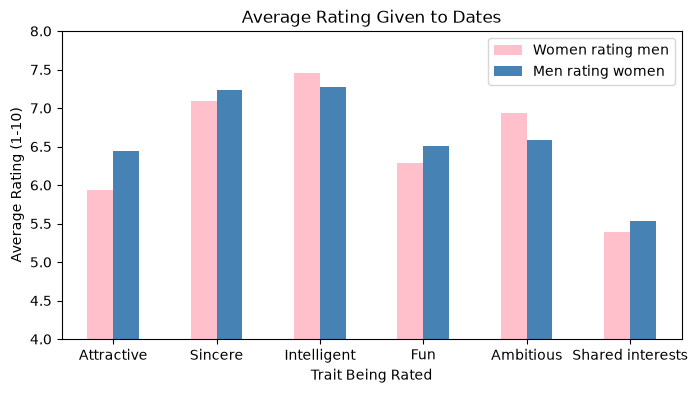

In [34]:
means = d_clean.groupby('gender')[traits].mean().T
means.columns = ['Women rating men', 'Men rating women']
means.index = ['Attractive', 'Sincere', 'Intelligent', 'Fun', 'Ambitious', 'Shared interests']

means.plot(kind='bar', color=['pink', 'steelblue'], figsize=(8, 4))
plt.ylim(4, 8)
plt.title('Average Rating Given to Dates')
plt.ylabel('Average Rating (1-10)')
plt.xlabel('Trait Being Rated')
plt.xticks(rotation=0)
plt.show()

According to the graph, men tend to give higher attractiveness ratings (6.9 vs 6.6), while women rate intelligence slightly higher. It's important to note that people who went on more dates count for more.